# LineSight
## Visual anomaly detection for production lines

**Kumar Waibhav Akshat** · kwa.waibhav@gmail.com

A reproducible tour of a real industrial image benchmark, normal-only Isolation Forest, independent calibration, and frozen-model evaluation. This notebook reads measured experiment outputs and runs inference; it does **not** retune from test results.

Run from the project checkout after dataset download, training and evaluation. Dataset and derived visuals: MVTec AD, CC BY-NC-SA 4.0.

In [1]:
from pathlib import Path
import csv, json, sys
ROOT = Path.cwd()
if not (ROOT / 'src/linesight').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from PIL import Image
from IPython.display import display, Markdown
from linesight.model import Detector, file_sha256
metrics = json.loads((ROOT/'reports/metrics.json').read_text())
frozen = json.loads((ROOT/'reports/frozen_model.json').read_text())
with (ROOT/'data/manifest.csv').open(newline='') as handle:
    rows = list(csv.DictReader(handle))
print('Frozen model:', frozen['model_version'])
assert file_sha256(ROOT/'artifacts/linesight.joblib') == frozen['artifact_sha256']
print('Frozen artifact checksum verified.')

Frozen model: ls-a5006862e1ce
Frozen artifact checksum verified.


## 1. Real data and split integrity

MVTec bottle contains 209 normal training images and 83 official test images. Only normal images enter development roles; synthetic tune defects stay in the tune role. Every image has a SHA-256 digest. Masks are for visual comparison only; this project does not claim validated defect segmentation.

In [2]:
from collections import Counter
print('Split counts:', dict(Counter(r['split'] for r in rows)))
print('Official test classes:', dict(Counter(r['defect_type'] for r in rows if r['split']=='test')))
assert all(r['label']=='0' for r in rows if r['split']!='test')
assert len({r['sha256'] for r in rows}) == len(rows)
print('No repeated image hashes; development partitions are normal-only.')

Split counts: {'test': 83, 'fit': 125, 'calibration': 42, 'tune': 42}
Official test classes: {'broken_large': 20, 'broken_small': 22, 'contamination': 21, 'good': 20}
No repeated image hashes; development partitions are normal-only.


## 2. Development and freeze

Images are resized to 192 × 192. A normal median/MAD reference yields color and gradient residual descriptors over a 12 × 12 patch grid. Isolation trees learn normal feature patterns. The selected image score aggregates patch scores; higher means more anomalous. Four candidates were compared using tune normals and three synthetic proxy defects per tune image.

In [3]:
selection = json.loads((ROOT/'reports/selection.json').read_text())
for run in selection['candidates']:
    print(f"{run['candidate']:18s} proxy AUROC={run['proxy_auroc']:.4f}")
print('Selected:', frozen['selected_candidate'])
print(json.dumps(frozen['calibration'], indent=2))

image_if           proxy AUROC=0.8152
patch_if_max       proxy AUROC=0.9211
patch_if_top4      proxy AUROC=0.8643
patch_if_top9      proxy AUROC=0.8054
Selected: patch_if_max
{
  "method": "split_conformal_upper_order_statistic",
  "alpha": 0.05,
  "n": 42,
  "rank_one_indexed": 41,
  "threshold": 0.73856190923971,
  "strict_decision": "score > threshold",
  "nominal_error_bound_under_exchangeability": 0.046511627906976744,
  "assumption": "Calibration and future nominal images must be exchangeable; drift invalidates coverage."
}


The strict `score > threshold` decision uses the upper order statistic $k=\lceil(n+1)(1-\alpha)\rceil$ from independent normal calibration scores. This nominal coverage assumption needs exchangeable future normal images. Lighting and camera drift can invalidate it. A score is not a defect probability.

## 3. Measured held-out results

In [4]:
for key in ['auroc','average_precision','precision','recall','f1','false_positive_rate']:
    print(f'{key:22s} {metrics[key]:.4f}')
print('Confusion matrix [normal, defect]:', metrics['confusion_matrix'])
print('95% intervals:', json.dumps(metrics['uncertainty']['intervals'], indent=2))
print('Model CPU timing (HTTP/decode excluded):', metrics['latency_ms'])

auroc                  0.9468
average_precision      0.9819
precision              0.9636
recall                 0.8413
f1                     0.8983
false_positive_rate    0.1000
Confusion matrix [normal, defect]: [[18, 2], [10, 53]]
95% intervals: {
  "auroc": [
    0.8857142857142857,
    0.9865277777777777
  ],
  "average_precision": [
    0.9611129987686876,
    0.9957972259393948
  ],
  "precision": [
    0.9122807017543859,
    1.0
  ],
  "recall": [
    0.746031746031746,
    0.9206349206349206
  ],
  "f1": [
    0.8363636363636363,
    0.95
  ]
}
Model CPU timing (HTTP/decode excluded): {'p50': 139.2137889999958, 'p95': 324.65972020006564, 'mean': 167.49739721685236, 'n': 83, 'batch_size': 1, 'warmup_count': 2, 'includes': 'RGB resize, reference descriptors and forest score', 'excludes': 'image decoding, upload, queue, SQLite, HTTP and camera capture', 'forest_threads': 1, 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39', 'processor': 'x86_64', 'hard_realtime_validated': Fals

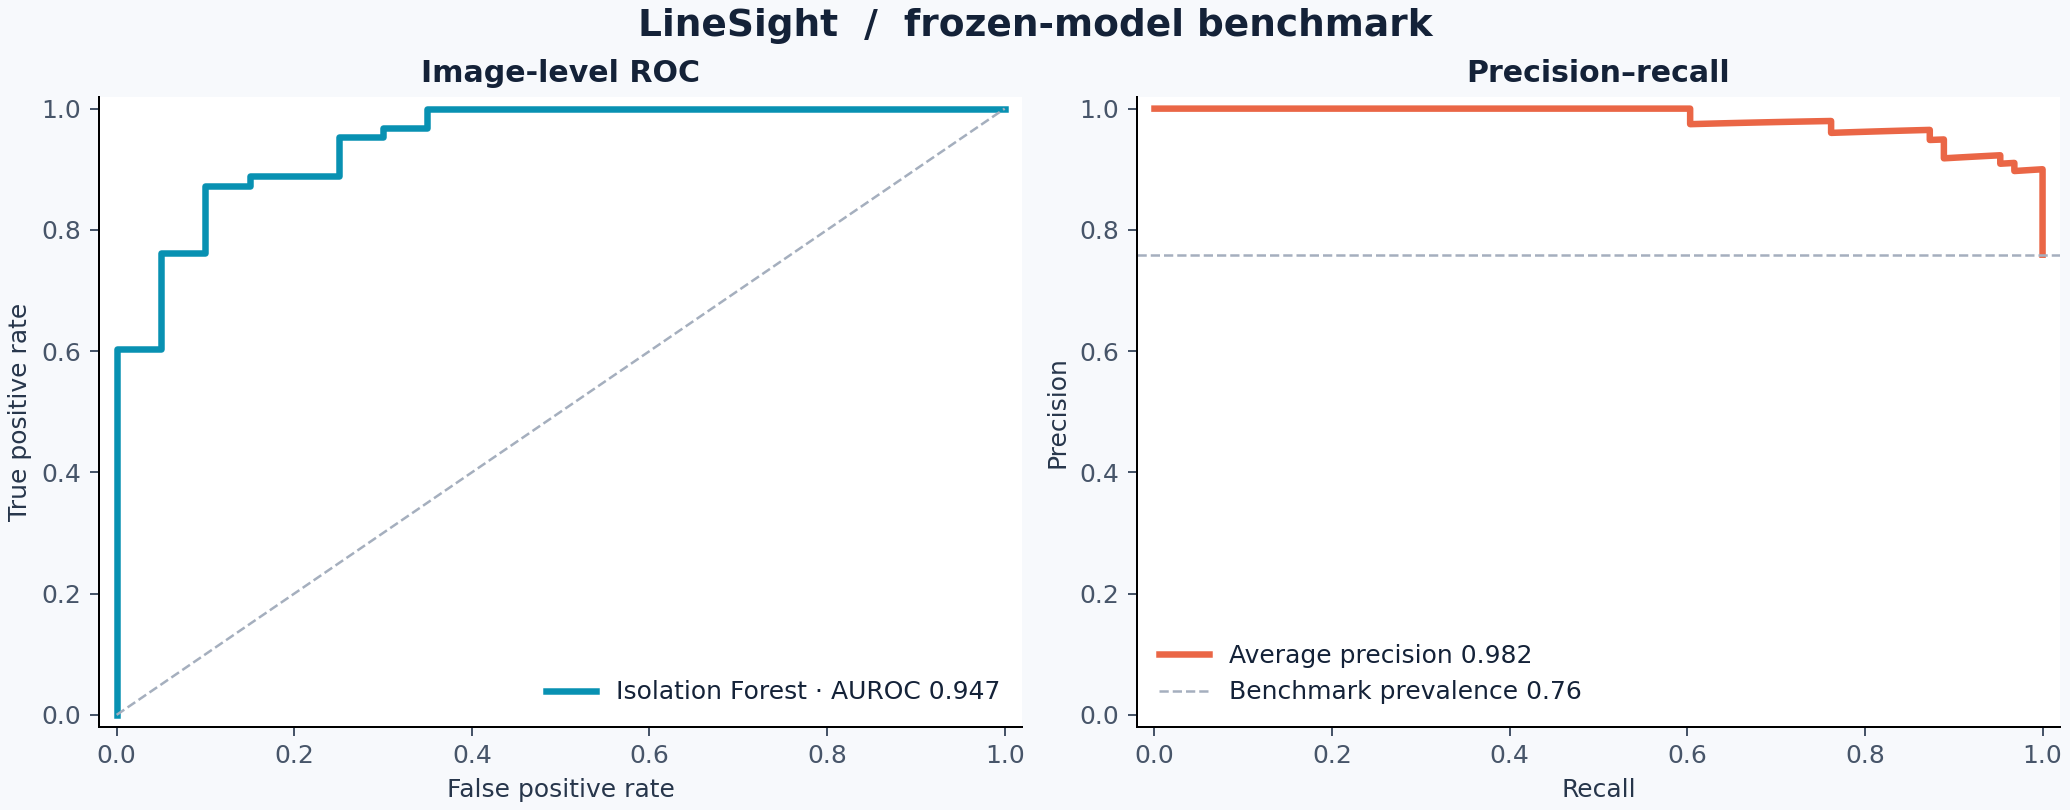

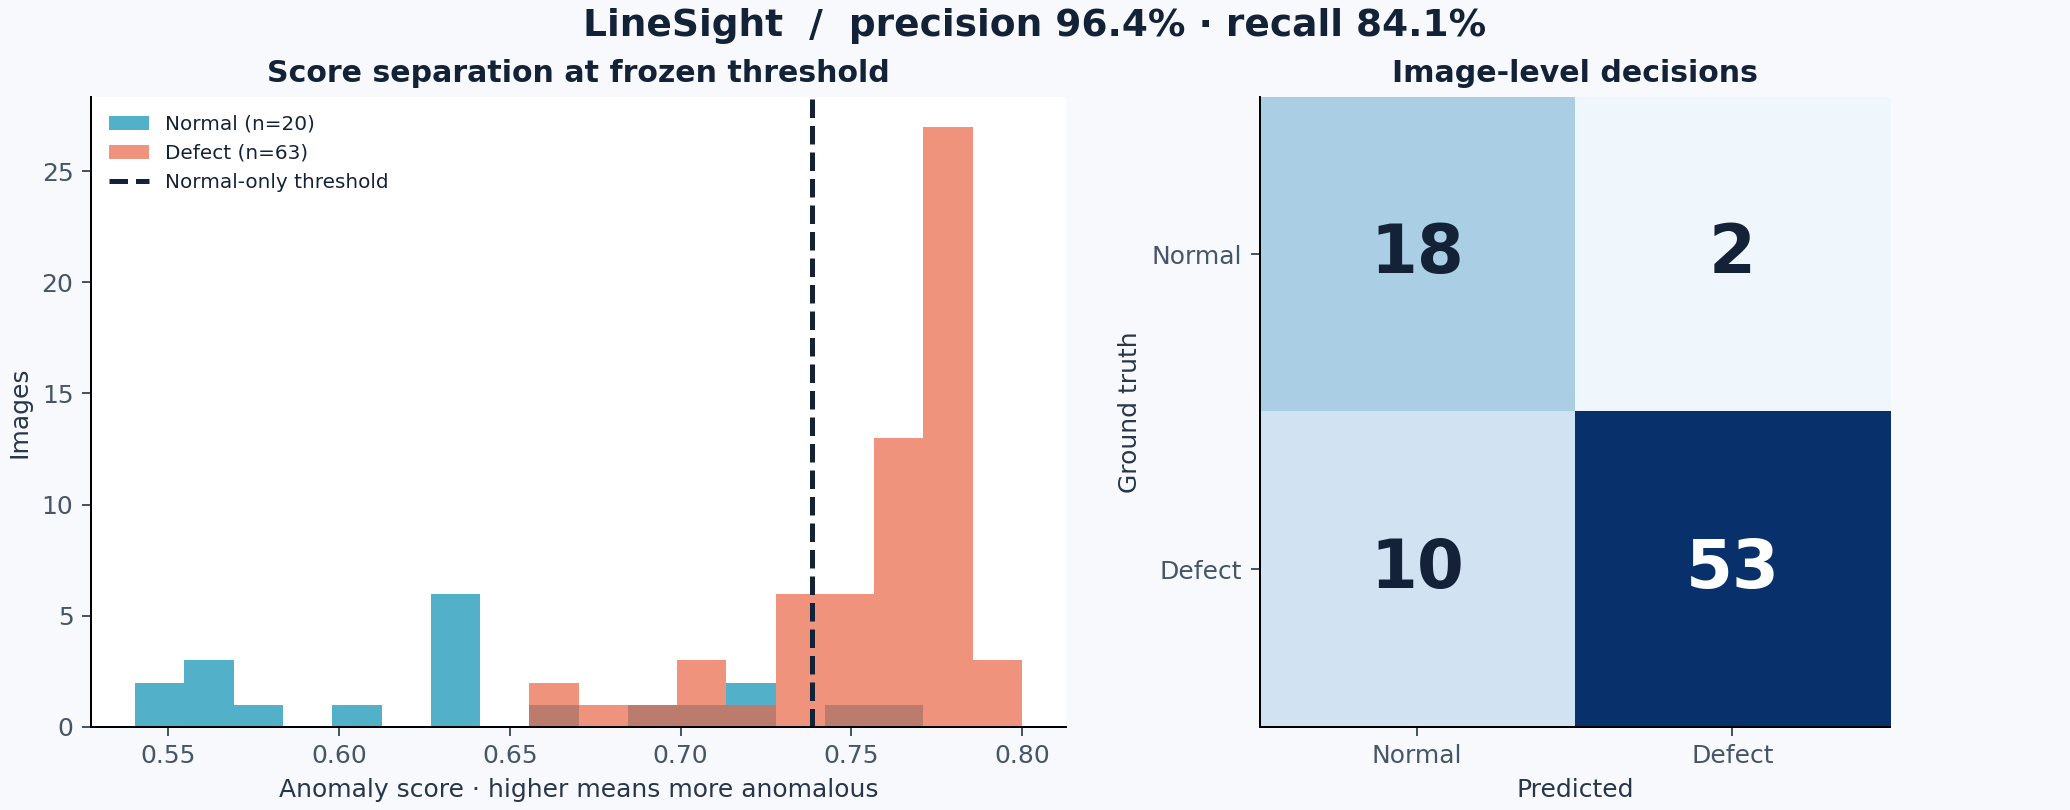

In [5]:
display(Image.open(ROOT/'reports/figures/roc_pr.png'))
display(Image.open(ROOT/'reports/figures/scores_confusion.png'))

## 4. Run an actual inspection

This deterministic demonstration uses the first recorded contamination sample after the model has been frozen and evaluated. It is a demonstration, not another model-selection step.

{'score': 0.7403021990984884, 'threshold': 0.73856190923971, 'is_anomaly': True, 'model_version': 'ls-a5006862e1ce', 'timing_ms': {'features_ms': 104.66616799976691, 'forest_ms': 18.26601999982813, 'total_ms': 122.93218799959504}, 'heatmap_kind': 'patch_isolation_score', 'score_is_probability': False}
Coarse heatmap: 12 x 12


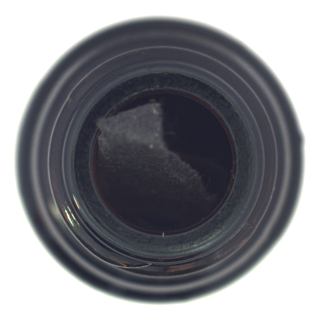

In [6]:
detector = Detector.load(ROOT/'artifacts/linesight.joblib')
sample = next(r for r in rows if r['split']=='test' and r['defect_type']=='contamination')
with Image.open(ROOT/sample['path']) as original:
    result = detector.inspect(original)
    display(original.resize((320,320)))
print({k:v for k,v in result.items() if k != 'heatmap'})
print('Coarse heatmap:', len(result['heatmap']), 'x', len(result['heatmap'][0]))

## 5. Evidence and failure analysis

The visualization places coarse patch evidence next to the dataset annotation. The overlay has not been evaluated as a pixel mask. Sensitivity tests keep the threshold fixed; they reveal deployment limits rather than creating a new selection loop.

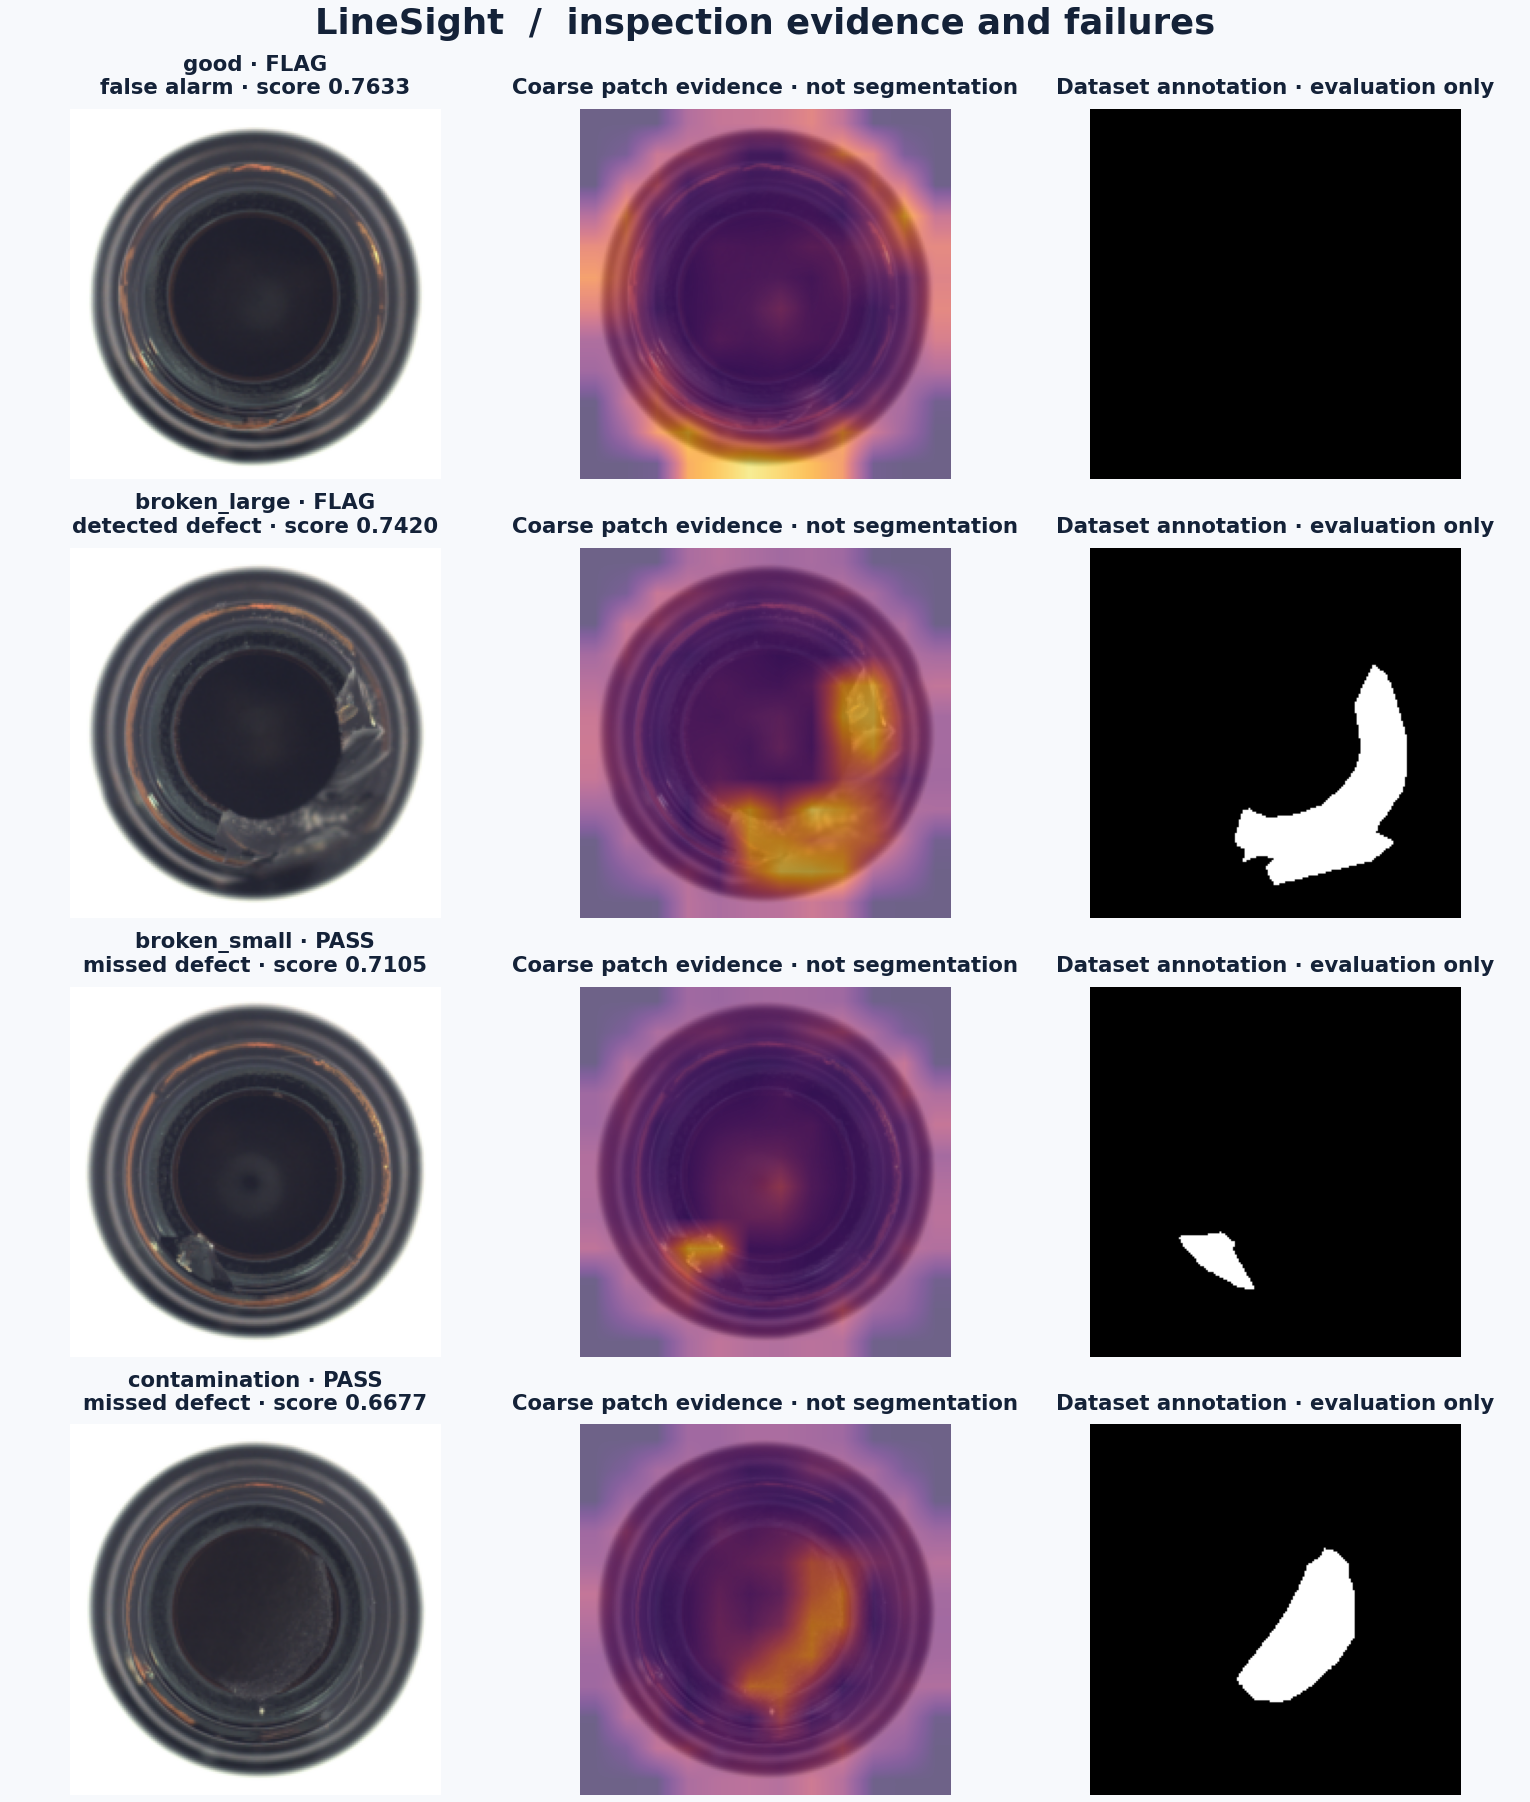

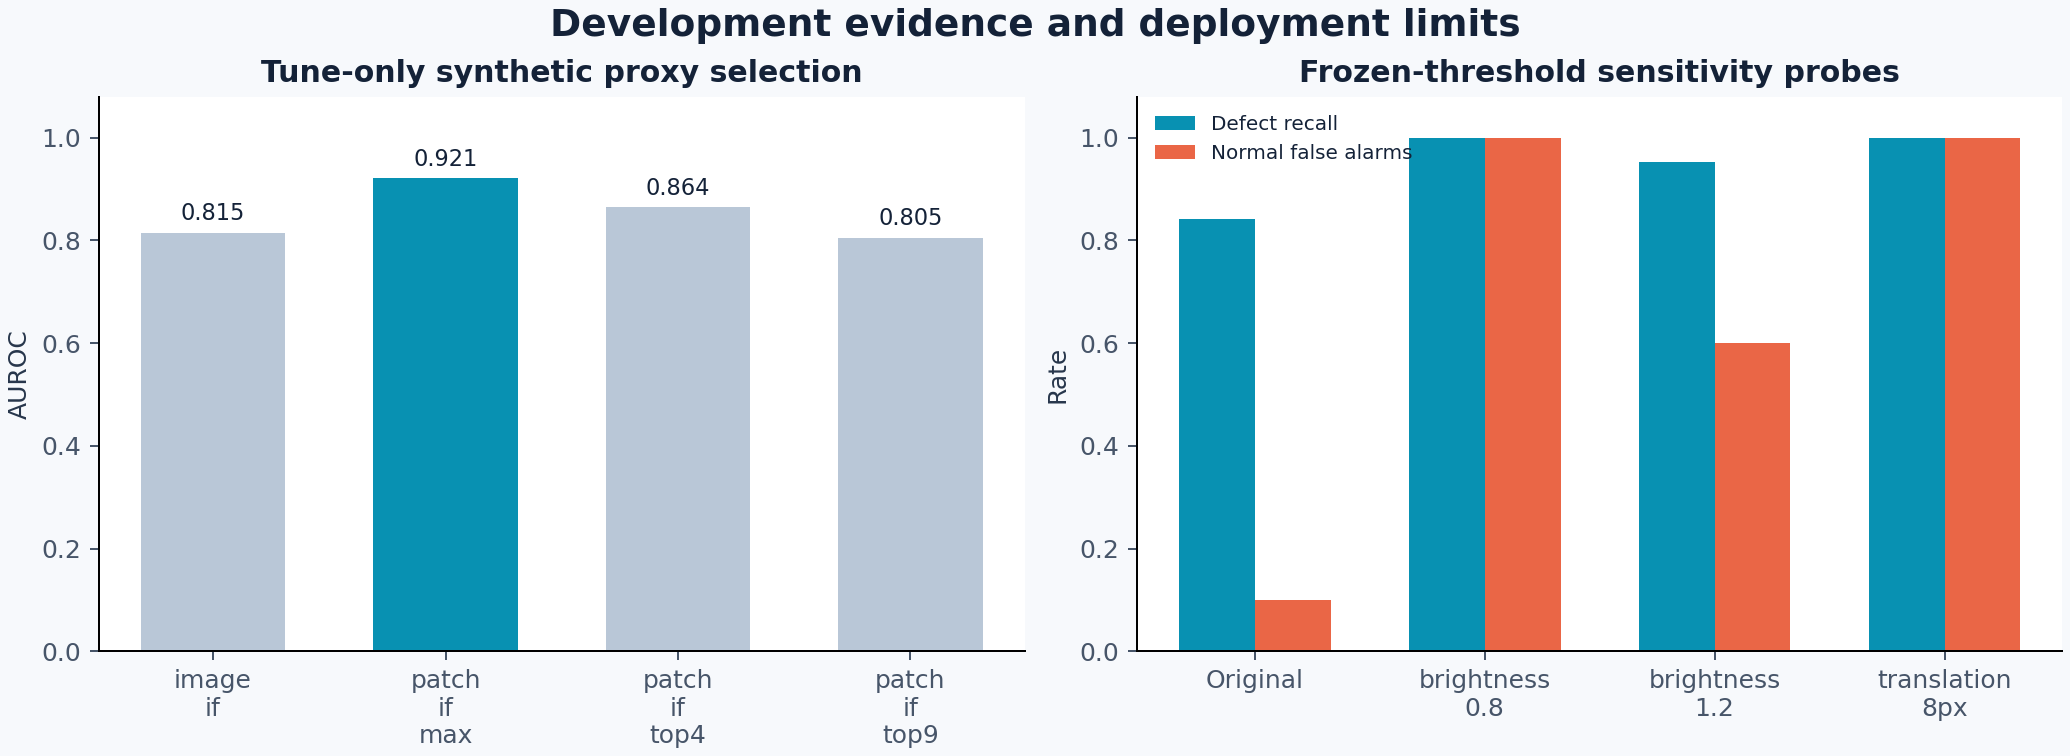

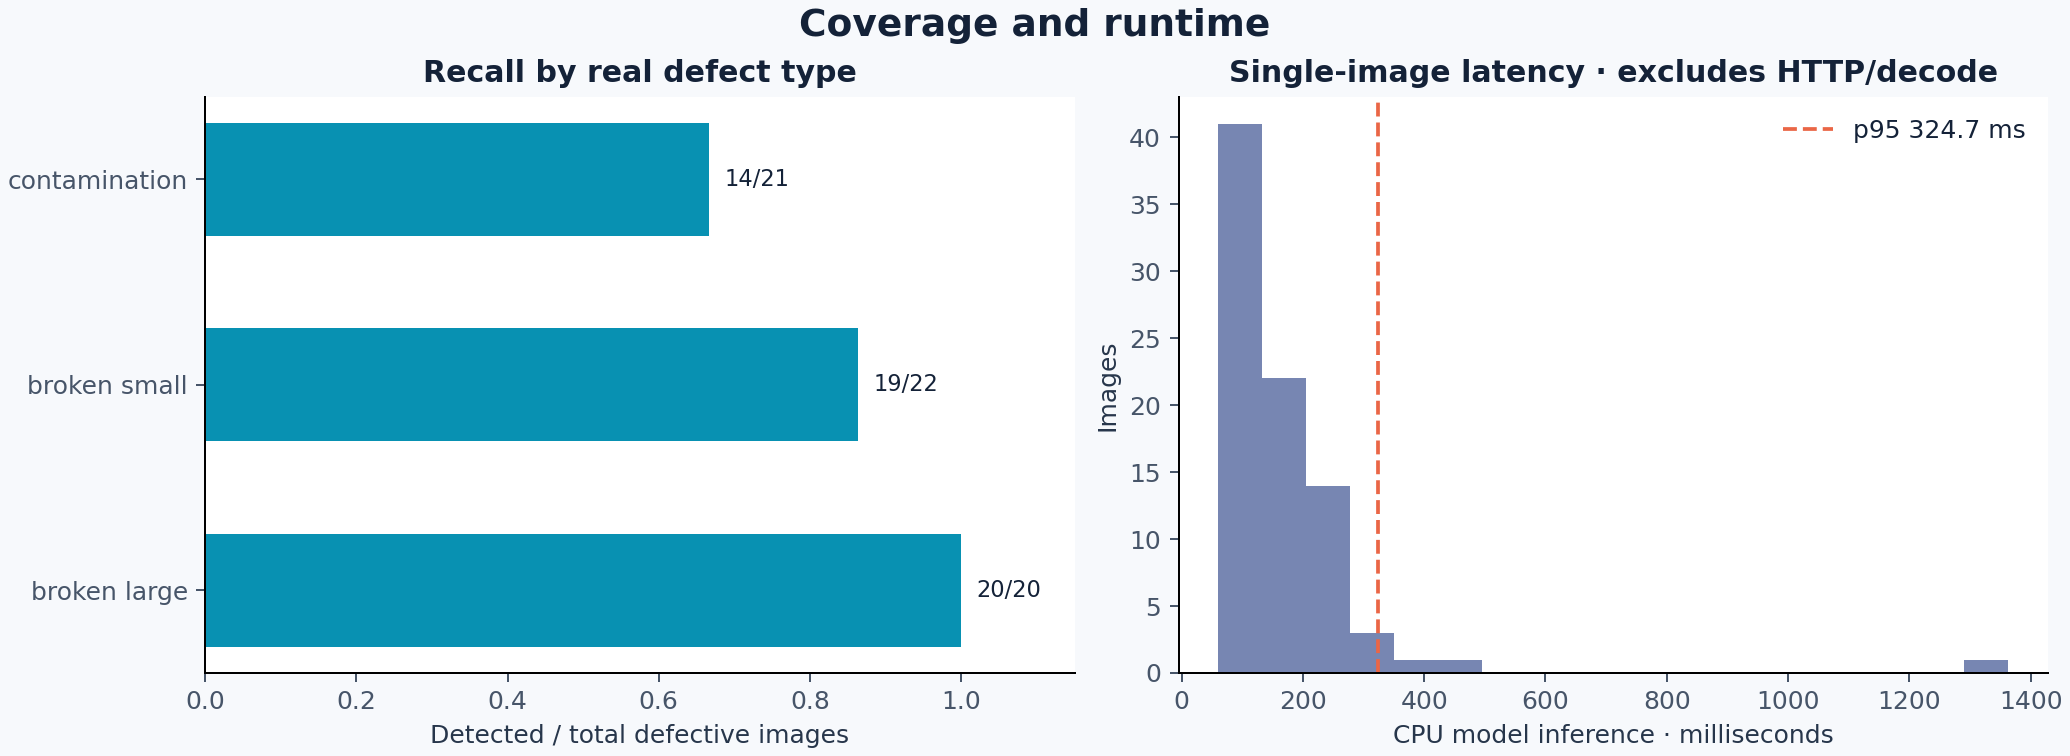

In [7]:
display(Image.open(ROOT/'reports/figures/inspection_examples.png'))
display(Image.open(ROOT/'reports/figures/development_robustness.png'))
display(Image.open(ROOT/'reports/figures/defects_latency.png'))

In [8]:
baseline = metrics['reference_baseline']
print('Simple residual baseline:', {k:baseline[k] for k in ['auroc','recall','f1']})
print('Per-defect coverage:', json.dumps(metrics['per_defect'], indent=2))
for limit in metrics['limitations']:
    print('-', limit)

Simple residual baseline: {'auroc': 0.9388888888888889, 'recall': 0.7619047619047619, 'f1': 0.8648648648648649}
Per-defect coverage: {
  "broken_large": {
    "n": 20,
    "detected": 20,
    "recall": 1.0,
    "recall_wilson95": [
      0.8388748419471806,
      1.0
    ]
  },
  "broken_small": {
    "n": 22,
    "detected": 19,
    "recall": 0.8636363636363636,
    "recall_wilson95": [
      0.6666501283342828,
      0.9525099628594474
    ]
  },
  "contamination": {
    "n": 21,
    "detected": 14,
    "recall": 0.6666666666666666,
    "recall_wilson95": [
      0.4537345197425524,
      0.8280524739491653
    ]
  }
}
- One fixed-view category; dataset replay is not a live factory validation.
- Official test has only 20 normal images; false-alarm uncertainty is large.
- Test defect prevalence differs from production and changes precision.
- Coarse patch evidence is not validated pixel segmentation.
- Brightness/pose drift can violate calibration assumptions and raise false alarms.
-

## 6. Reproduce and use

```bash
python -m pip install -e '.[dev,notebook]'
python scripts/download_data.py
python scripts/train.py
python scripts/evaluate.py
python -m pytest -q
python scripts/serve.py
```

Open http://127.0.0.1:8000 for uploads, recorded dataset replay, sampled camera frames, and local decision history. A new camera needs its own normal collection and independent evaluation. This delivery has not been pushed to GitHub or published externally.

References: [MVTec AD](https://www.mvtec.com/research-teaching/datasets/mvtec-ad) · [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)